# Lab 1 mở rộng — EDA, PCA và khai phá dữ liệu FashionMNIST

**Nhóm 4 | Notebook bổ sung cho `02_lab_demo.ipynb`**

Mục tiêu: khám phá dữ liệu bằng thống kê, hình ảnh, PCA, t-SNE, phân cụm, phát hiện bất thường và đánh giá đặc trưng. **Không huấn luyện lại hoặc thay đổi checkpoint MLP**.

Nguồn dữ liệu: FashionMNIST, 60.000 ảnh train gốc (trong Lab 1 chia 54.000 train / 6.000 validation), 10.000 ảnh test. Để tránh data leakage, các phép học biến đổi (PCA, scaler, K-Means) chỉ fit trên **train split**; các phân tích minh họa chủ yếu lấy mẫu train. Test không dùng để lựa chọn tham số.

**Cách chạy:** từ thư mục gốc repo, cài `pip install torch torchvision numpy pandas matplotlib seaborn scikit-learn scipy ipykernel` (UMAP tùy chọn: `pip install umap-learn`). Notebook tự nhận thư mục gốc khi chạy từ `notebooks/` hoặc root. Lần đầu có thể tải FashionMNIST nếu chưa có. Các phép t-SNE/UMAP/silhouette chạy trên mẫu nhỏ để phù hợp CPU.

In [13]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.datasets import FashionMNIST
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, confusion_matrix
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA_ROOT = ROOT / "data"
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
EDA_SAMPLE = 6000
EMBED_SAMPLE = 1800
print('Root:', ROOT)
print('Seed:', SEED)

Root: D:\Mon
Seed: 42


## 1. Nạp dữ liệu và giữ nguyên split Lab 1
Ưu tiên `outputs/split_indices.json` của nhóm. Nếu thiếu, tái tạo split với seed 42 để **khám phá**, nhưng nên dùng file split gốc khi đối chiếu kết quả Lab 1.

In [14]:
train_raw = FashionMNIST(root=str(DATA_ROOT), train=True, download=True)
test_raw = FashionMNIST(root=str(DATA_ROOT), train=False, download=True)
X_all = train_raw.data.numpy().astype(np.float32) / 255.0  # (60000,28,28)
y_all = train_raw.targets.numpy().astype(int)
X_test = test_raw.data.numpy().astype(np.float32) / 255.0
y_test = test_raw.targets.numpy().astype(int)
split_file = ROOT / 'outputs' / 'split_indices.json'
if split_file.exists():
    split = json.loads(split_file.read_text(encoding='utf-8'))
    train_idx = np.asarray(split['train_indices'], dtype=int)
    val_idx = np.asarray(split['val_indices'], dtype=int)
    print('Using project split:', split_file)
else:
    import torch
    perm = torch.randperm(len(y_all), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx = perm[:54000], perm[54000:60000]
    print('WARNING: project split not found; recreated with torch seed 42')
assert len(train_idx)==54000 and len(val_idx)==6000
assert len(np.intersect1d(train_idx,val_idx))==0
assert len(np.unique(np.r_[train_idx,val_idx]))==60000
sample_idx = rng.choice(train_idx, size=min(EDA_SAMPLE,len(train_idx)), replace=False)
X = X_all[sample_idx].reshape(-1,784)
y = y_all[sample_idx]
print('Train / val / test:', len(train_idx), len(val_idx), len(y_test))
print('EDA sample:', X.shape, 'dtype:', X.dtype, 'range:', (X.min(),X.max()))

Train / val / test: 54000 6000 10000
EDA sample: (6000, 784) dtype: float32 range: (np.float32(0.0), np.float32(1.0))


## 2. Kiểm tra chất lượng dữ liệu
FashionMNIST là dữ liệu ảnh nên kiểm tra missing/NaN, pixel ngoài miền, ảnh trùng hoàn toàn và số lượng từng lớp. Ảnh trùng không nhất thiết là lỗi dữ liệu.

NaN: 0 Inf: 0
Out-of-range pixels: 0
Exact duplicate images in sample: 0


,class,count
0,T-shirt/top,619
1,Trouser,560
2,Pullover,599
3,Dress,595
4,Coat,600
5,Sandal,654
6,Shirt,606
7,Sneaker,608
8,Bag,577
9,Ankle boot,582


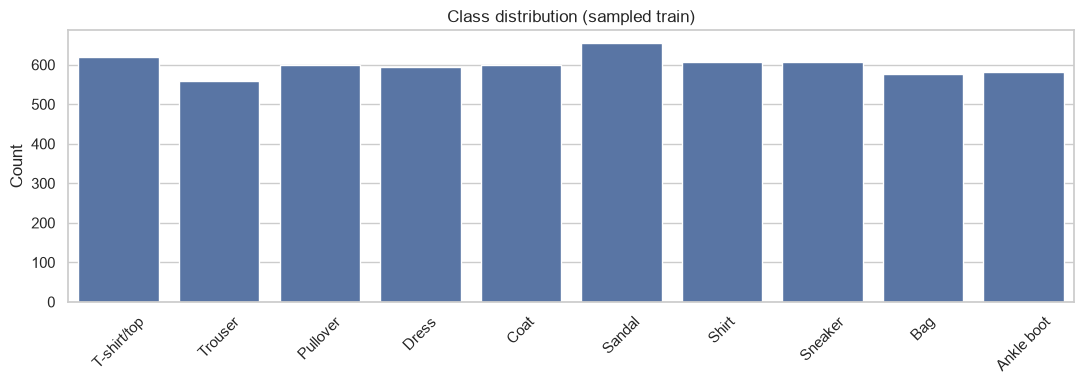

In [15]:
print('NaN:', int(np.isnan(X).sum()), 'Inf:', int(np.isinf(X).sum()))
print('Out-of-range pixels:', int(((X<0)|(X>1)).sum()))
print('Exact duplicate images in sample:', int(len(X)-len(np.unique(X,axis=0))))
counts = pd.Series(y).value_counts().sort_index()
display(pd.DataFrame({'class':CLASS_NAMES,'count':counts.reindex(range(10),fill_value=0).values}))
fig,ax=plt.subplots(figsize=(11,4)); sns.barplot(x=CLASS_NAMES,y=counts.reindex(range(10),fill_value=0).values,ax=ax)
ax.tick_params(axis='x',rotation=45);ax.set(title='Class distribution (sampled train)',ylabel='Count');plt.tight_layout();plt.show()

## 3. Khám phá ảnh và thống kê đơn biến

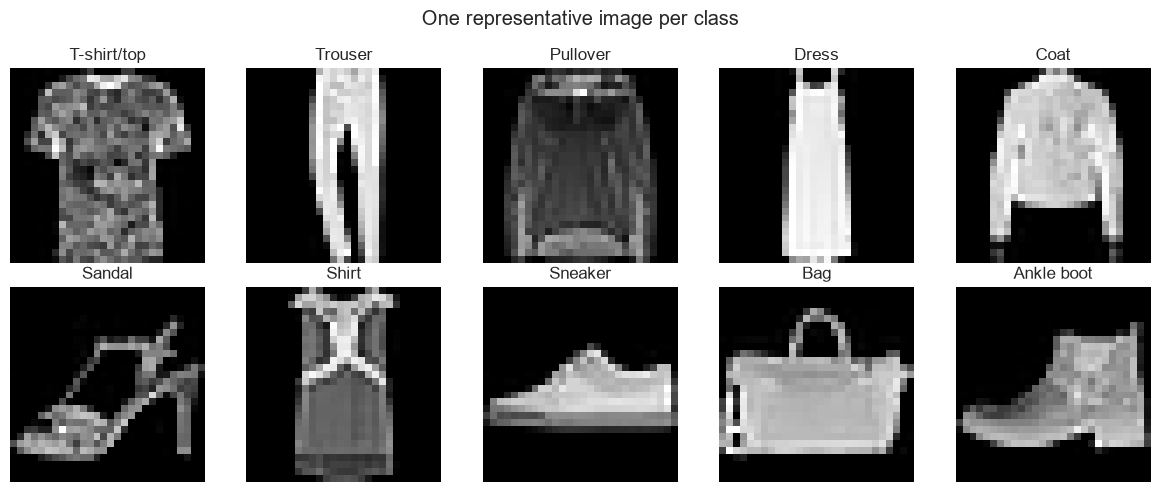

mean_brightness        contrast        foreground_ratio       
                       mean    std     mean    std             mean    std
class_name                                                                
Ankle boot            0.307  0.071    0.362  0.051            0.423  0.071
Bag                   0.349  0.114    0.338  0.064            0.509  0.122
Coat                  0.383  0.103    0.353  0.073            0.539  0.098
Dress                 0.260  0.085    0.337  0.073            0.372  0.091
Pullover              0.381  0.124    0.326  0.087            0.569  0.119
Sandal                0.135  0.060    0.246  0.060            0.222  0.087
Shirt                 0.333  0.127    0.303  0.092            0.524  0.133
Sneaker               0.167  0.049    0.285  0.056            0.254  0.060
T-shirt/top           0.324  0.112    0.320  0.088            0.494  0.112
Trouser               0.217  0.052    0.330  0.057            0.311  0.055

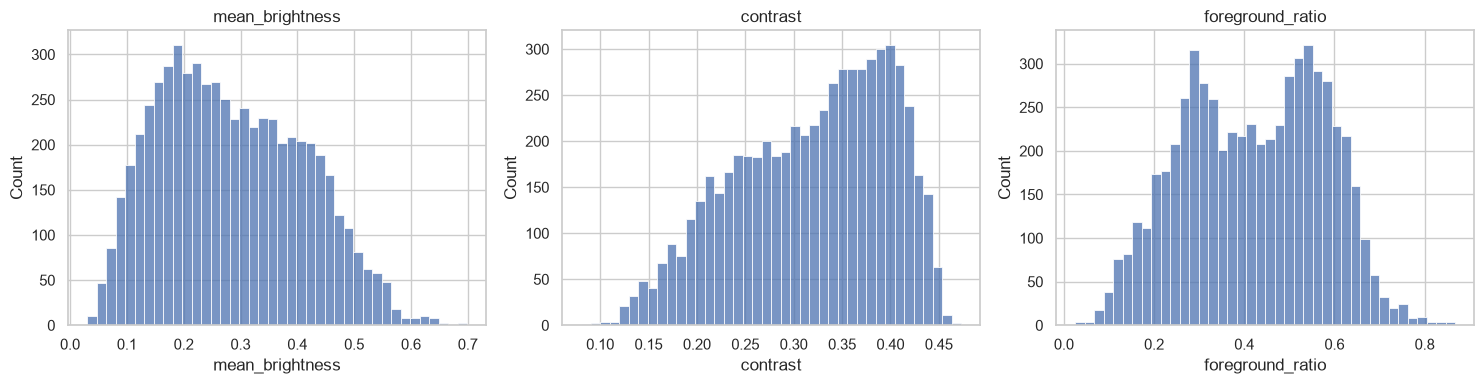

In [16]:
fig,axes=plt.subplots(2,5,figsize=(12,5))
for k,ax in enumerate(axes.flat):
    ids=np.where(y==k)[0]
    if len(ids):ax.imshow(X[ids[0]].reshape(28,28),cmap='gray',vmin=0,vmax=1)
    ax.set_title(CLASS_NAMES[k]);ax.axis('off')
plt.suptitle('One representative image per class');plt.tight_layout();plt.show()
brightness=X.mean(axis=1); contrast=X.std(axis=1); foreground=(X>0.2).mean(axis=1)
features=pd.DataFrame({'class_id':y,'class_name':[CLASS_NAMES[i] for i in y],
                       'mean_brightness':brightness,'contrast':contrast,'foreground_ratio':foreground})
display(features.groupby('class_name')[['mean_brightness','contrast','foreground_ratio']].agg(['mean','std']).round(3))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['mean_brightness','contrast','foreground_ratio']):
    sns.histplot(features[col],bins=40,ax=ax);ax.set_title(col)
plt.tight_layout();plt.show()

## 4. Phân tích ảnh trung bình, độ lệch chuẩn và pixel
Bản đồ độ lệch chuẩn thể hiện vùng ảnh biến đổi nhiều nhất; không trực tiếp chứng minh pixel đó quan trọng nhất cho dự đoán.

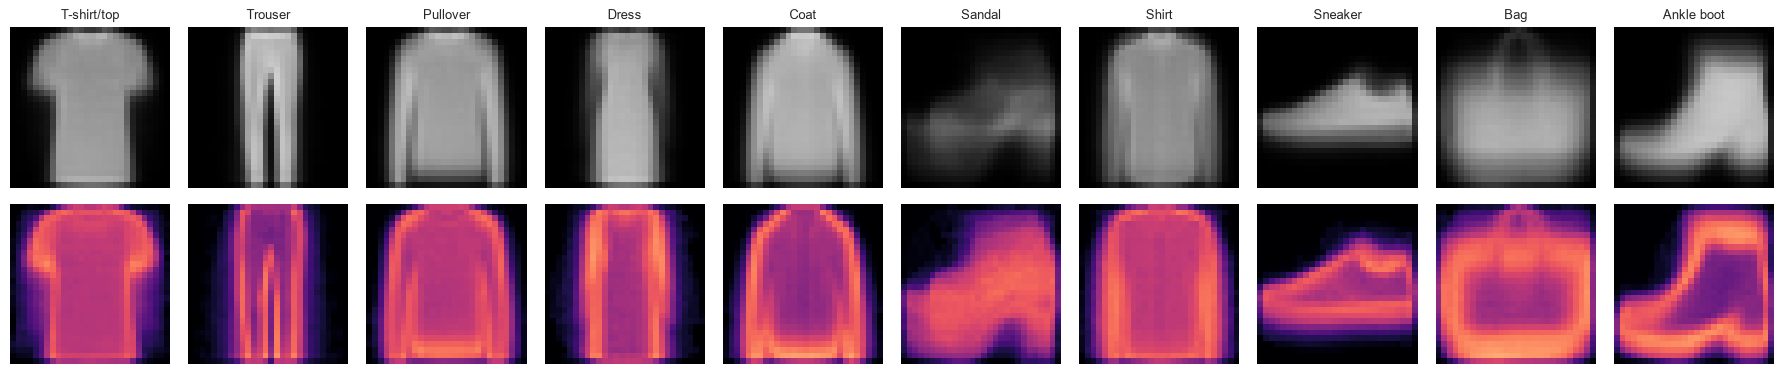

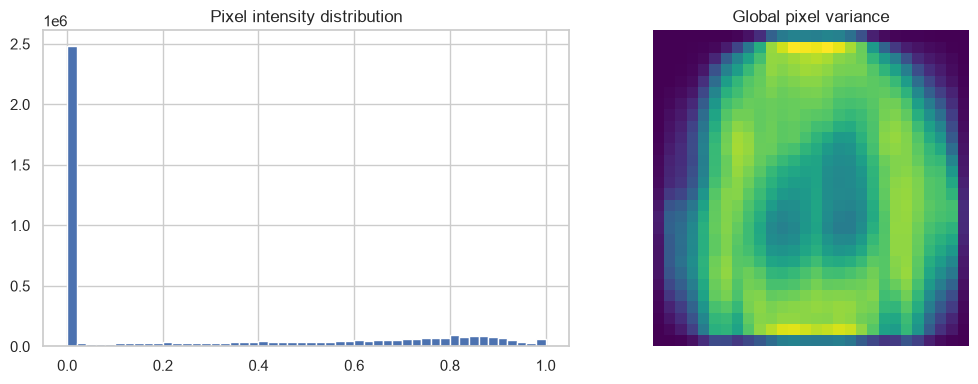

In [17]:
fig,axes=plt.subplots(2,10,figsize=(18,4))
for k in range(10):
    subset=X[y==k]
    axes[0,k].imshow(subset.mean(axis=0).reshape(28,28),cmap='gray',vmin=0,vmax=1)
    axes[1,k].imshow(subset.std(axis=0).reshape(28,28),cmap='magma',vmin=0,vmax=.5)
    axes[0,k].set_title(CLASS_NAMES[k],fontsize=9)
    axes[0,k].axis('off');axes[1,k].axis('off')
axes[0,0].set_ylabel('Mean');axes[1,0].set_ylabel('Std');plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(X.ravel(),bins=50);axes[0].set_title('Pixel intensity distribution')
axes[1].imshow(X.var(axis=0).reshape(28,28),cmap='viridis');axes[1].set_title('Global pixel variance');axes[1].axis('off')
plt.tight_layout();plt.show()

## 5. Đặc trưng thủ công và tương quan
Độ sáng, tương phản và tỷ lệ pixel nổi bật là các mô tả đơn giản; không phải đặc trưng do MLP tự học.

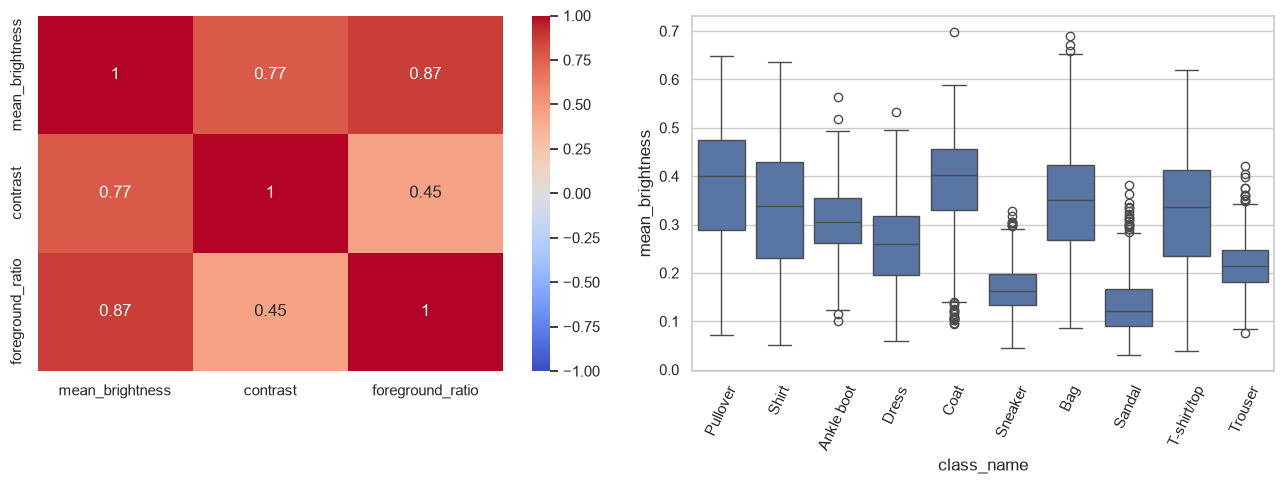

In [18]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.heatmap(features[['mean_brightness','contrast','foreground_ratio']].corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1,ax=axes[0])
sns.boxplot(data=features,x='class_name',y='mean_brightness',ax=axes[1]);axes[1].tick_params(axis='x',rotation=65)
plt.tight_layout();plt.show()

## 6. PCA: số chiều, phương sai giải thích và các thành phần chính
PCA được **fit chỉ trên train sample**. PCA mặc định trừ trung bình từng pixel; không chuẩn hóa từng pixel về unit variance vì ảnh đã cùng thang [0,1].

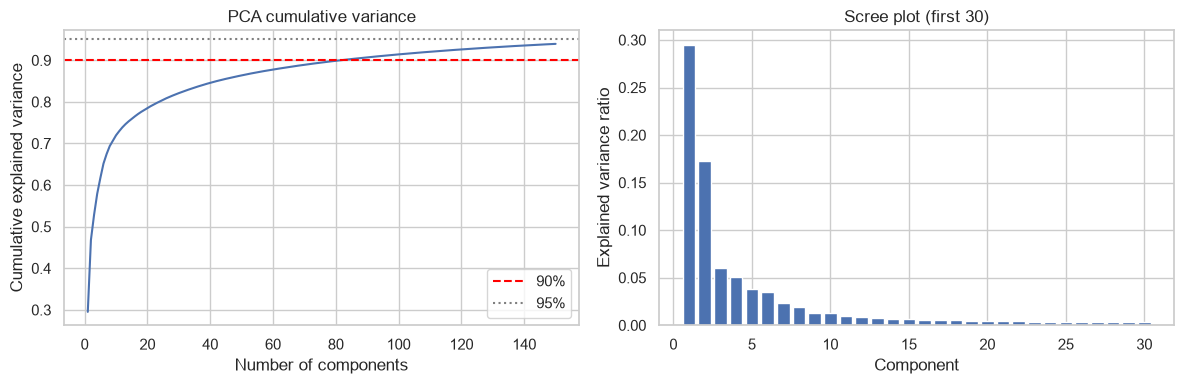

80% variance: 24 components
90% variance: 82 components
95% variance: > 150 (not reached)


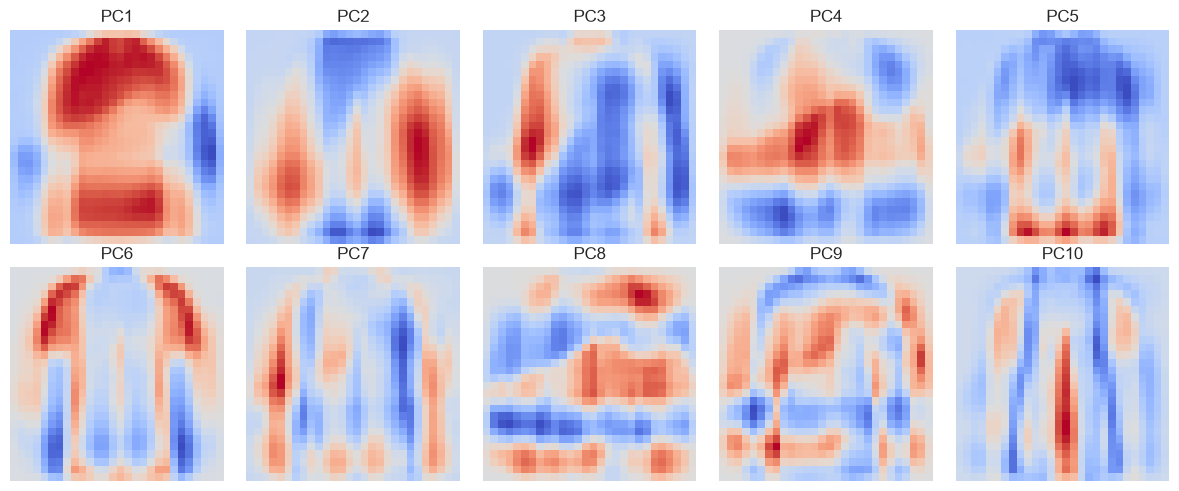

In [19]:
pca=PCA(n_components=min(150,len(X)-1,784),svd_solver='randomized',random_state=SEED)
Z=pca.fit_transform(X)
explained=np.cumsum(pca.explained_variance_ratio_)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(np.arange(1,len(explained)+1),explained);axes[0].axhline(.9,color='red',ls='--',label='90%');axes[0].axhline(.95,color='gray',ls=':',label='95%')
axes[0].set(xlabel='Number of components',ylabel='Cumulative explained variance',title='PCA cumulative variance');axes[0].legend()
axes[1].bar(np.arange(1,31),pca.explained_variance_ratio_[:30]);axes[1].set(xlabel='Component',ylabel='Explained variance ratio',title='Scree plot (first 30)')
plt.tight_layout();plt.show()
for threshold in (.8,.9,.95):
    idx=np.searchsorted(explained,threshold)
    print(f'{threshold:.0%} variance:',f'{idx+1} components' if idx<len(explained) else f'> {len(explained)} (not reached)')
fig,axes=plt.subplots(2,5,figsize=(12,5))
for k,ax in enumerate(axes.flat):
    ax.imshow(pca.components_[k].reshape(28,28),cmap='coolwarm');ax.set_title(f'PC{k+1}');ax.axis('off')
plt.tight_layout();plt.show()

## 7. PCA 2D/3D và tái tạo ảnh
Màu thể hiện nhãn thật, không phải kết quả phân cụm. PCA 2D là phép chiếu có mất thông tin.

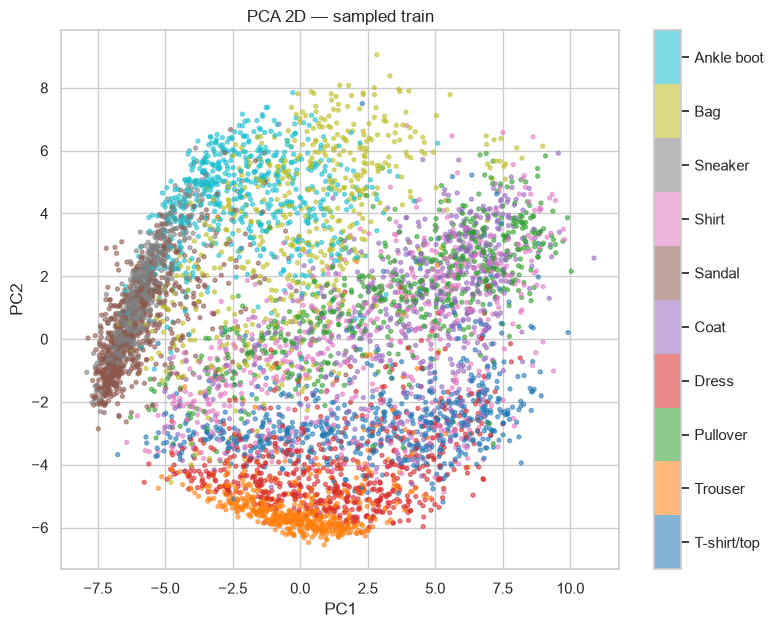

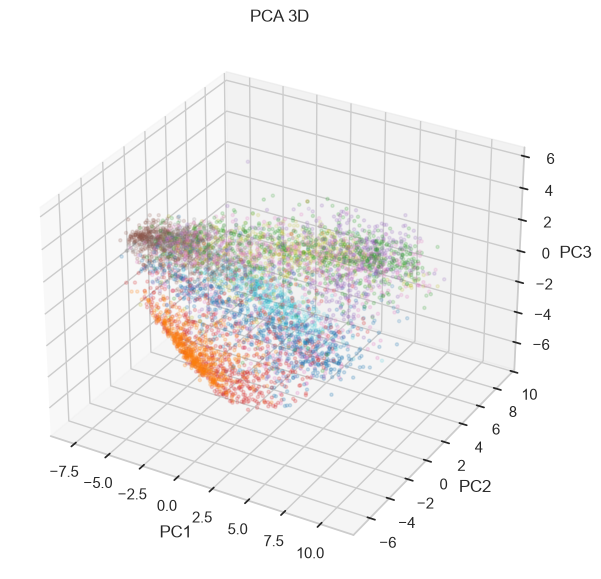

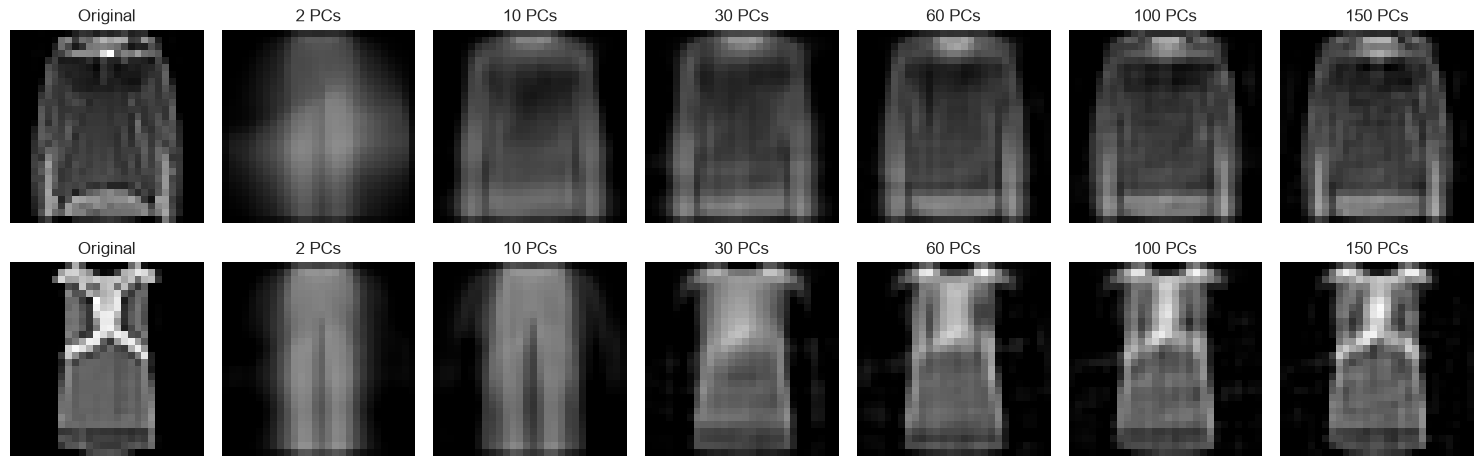

In [20]:
fig,ax=plt.subplots(figsize=(9,7))
sc=ax.scatter(Z[:,0],Z[:,1],c=y,s=8,alpha=.55,cmap='tab10',vmin=-.5,vmax=9.5)
ax.set(xlabel='PC1',ylabel='PC2',title='PCA 2D — sampled train');cb=plt.colorbar(sc,ax=ax,ticks=range(10));cb.ax.set_yticklabels(CLASS_NAMES);plt.show()
fig=plt.figure(figsize=(9,7));ax=fig.add_subplot(111,projection='3d')
ax.scatter(Z[:,0],Z[:,1],Z[:,2],c=y,s=5,alpha=.45,cmap='tab10',vmin=-.5,vmax=9.5)
ax.set(xlabel='PC1',ylabel='PC2',zlabel='PC3',title='PCA 3D');plt.show()
components_to_show=[2,10,30,60,100,150]
fig,axes=plt.subplots(2,len(components_to_show)+1,figsize=(15,5))
for row in range(2):
    original=X[row];axes[row,0].imshow(original.reshape(28,28),cmap='gray',vmin=0,vmax=1)
    axes[row,0].set_title('Original');axes[row,0].axis('off')
    for col,k in enumerate(components_to_show,1):
        rec=pca.mean_ + Z[row,:k] @ pca.components_[:k]
        axes[row,col].imshow(np.clip(rec.reshape(28,28),0,1),cmap='gray',vmin=0,vmax=1)
        axes[row,col].set_title(f'{k} PCs');axes[row,col].axis('off')
plt.tight_layout();plt.show()

## 8. t-SNE và UMAP (tùy chọn)
Giảm chiều bằng PCA 50 trước t-SNE để giảm thời gian chạy. t-SNE/UMAP dùng cho trực quan hóa; khoảng cách giữa các cụm trên đồ thị không nên diễn giải như khoảng cách toàn cục chính xác.

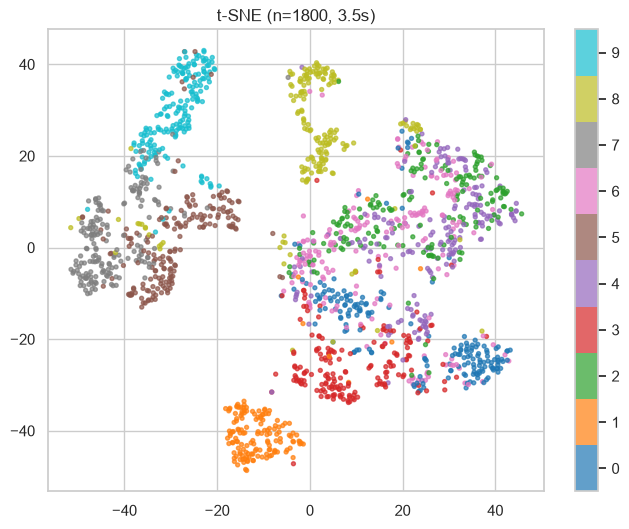

UMAP skipped: install umap-learn if needed


In [21]:
embed_idx=rng.choice(len(X),size=min(EMBED_SAMPLE,len(X)),replace=False)
X_embed=Z[embed_idx,:min(50,Z.shape[1])]
y_embed=y[embed_idx]
start=time.time()
tsne=TSNE(n_components=2,perplexity=30,learning_rate='auto',init='pca',random_state=SEED)
T=tsne.fit_transform(X_embed)
fig,ax=plt.subplots(figsize=(8,6));sc=ax.scatter(T[:,0],T[:,1],c=y_embed,s=8,alpha=.7,cmap='tab10',vmin=-.5,vmax=9.5)
ax.set_title(f't-SNE (n={len(T)}, {time.time()-start:.1f}s)');plt.colorbar(sc,ax=ax,ticks=range(10));plt.show()
try:
    import umap
    U=umap.UMAP(n_neighbors=15,min_dist=0.1,n_components=2,random_state=SEED).fit_transform(X_embed)
    fig,ax=plt.subplots(figsize=(8,6));sc=ax.scatter(U[:,0],U[:,1],c=y_embed,s=8,alpha=.7,cmap='tab10',vmin=-.5,vmax=9.5)
    ax.set_title('UMAP (optional)');plt.colorbar(sc,ax=ax,ticks=range(10));plt.show()
except ImportError:
    print('UMAP skipped: install umap-learn if needed')

## 9. Phân cụm không giám sát (K-Means)
K-Means fit trên PCA 50 chiều, sau đó đối chiếu cụm với nhãn thật chỉ để **đánh giá sau phân cụm**. ARI/NMI không cần gán tên lớp cho cụm; cluster ID không phải nhãn dự đoán.

ARI: 0.3489 NMI: 0.5177


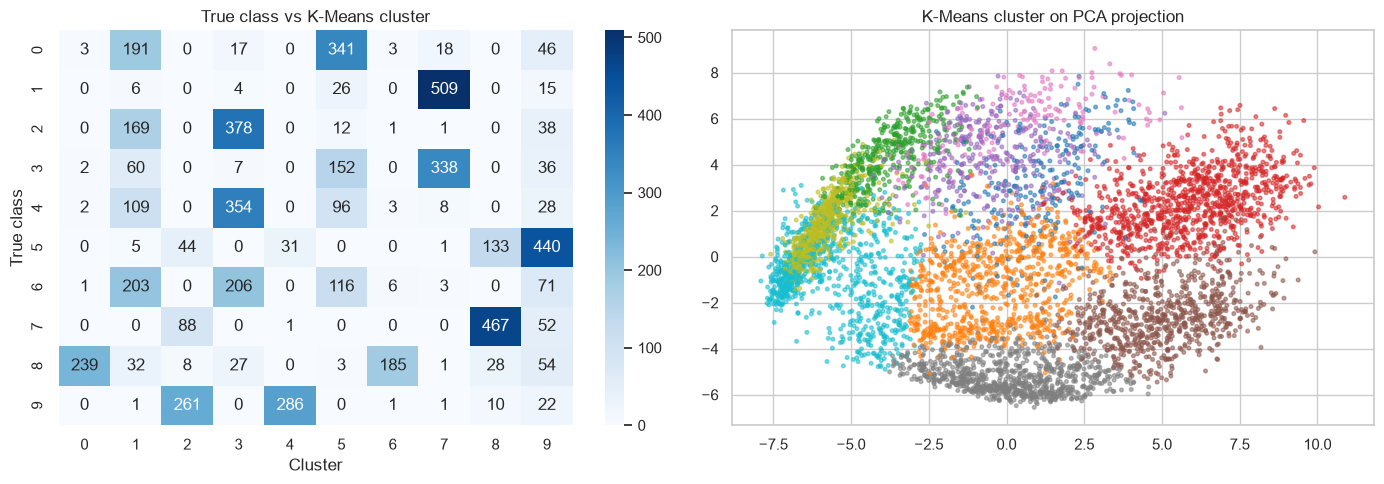

Silhouette (sample): 0.2037


In [22]:
K=min(50,Z.shape[1]);cluster_data=Z[:,:K]
km=KMeans(n_clusters=10,random_state=SEED,n_init=10)
clusters=km.fit_predict(cluster_data)
ari=adjusted_rand_score(y,clusters);nmi=normalized_mutual_info_score(y,clusters)
print('ARI:',round(ari,4),'NMI:',round(nmi,4))
ct=pd.crosstab(pd.Series(y,name='True class'),pd.Series(clusters,name='Cluster'))
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(ct,annot=True,fmt='d',cmap='Blues',ax=axes[0]);axes[0].set_title('True class vs K-Means cluster')
axes[1].scatter(Z[:,0],Z[:,1],c=clusters,cmap='tab10',s=7,alpha=.55);axes[1].set_title('K-Means cluster on PCA projection')
plt.tight_layout();plt.show()
# silhouette on subsample to limit O(n^2) distance calculations
sil_idx=rng.choice(len(X),size=min(1500,len(X)),replace=False)
print('Silhouette (sample):',round(silhouette_score(cluster_data[sil_idx],clusters[sil_idx]),4))

## 10. Phát hiện ảnh bất thường
Dùng lỗi tái tạo PCA làm điểm bất thường (heuristic). Top 12 là các ảnh khó tái tạo nhất trong sample, **không có nghĩa dữ liệu bị gán nhãn sai**.

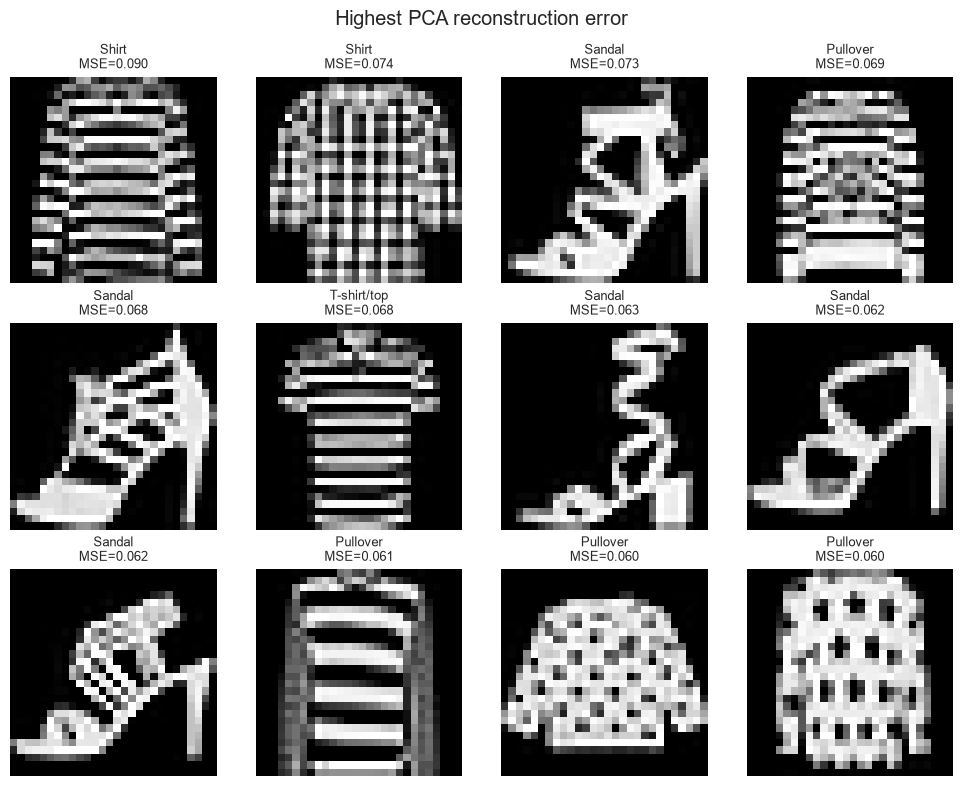

count    6000.000000
mean        0.015541
std         0.008468
min         0.002331
50%         0.013537
90%         0.025958
95%         0.031612
99%         0.045197
max         0.089925
dtype: float64


In [23]:
k = 30
reconstructed = pca.mean_ + Z[:, :k] @ pca.components_[:k]
reconstruction_error = ((X - reconstructed) ** 2).mean(axis=1)
order = np.argsort(reconstruction_error)[-12:][::-1]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, i in zip(axes.flat, order):
    ax.imshow(
        X[i].reshape(28, 28),
        cmap='gray',
        vmin=0,
        vmax=1
    )
    ax.set_title(
        f"{CLASS_NAMES[y[i]]}\nMSE={reconstruction_error[i]:.3f}",
        fontsize=9
    )
    ax.axis('off')
plt.suptitle('Highest PCA reconstruction error')
plt.tight_layout()
plt.show()
print(
    pd.Series(reconstruction_error).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

## 11. Gợi ý câu hỏi nghiên cứu và tổng kết
**Diễn giải có thể kiểm chứng từ kết quả chạy thực tế:**

1. Các lớp nào dễ chồng lấn trên PCA 2D / t-SNE?
2. Cần bao nhiêu thành phần chính để giữ 90% phương sai (trong phạm vi số PC đã fit)?
3. PCA 30/60/100 PC làm mất chi tiết ảnh như thế nào?
4. K-Means có khớp các nhãn quần áo hay không? Vì sao không thể đồng nhất cluster với class?
5. Những ảnh có reconstruction error cao có thực sự bất thường hay chỉ phức tạp?

**Giới hạn:** EDA trên mẫu 6.000 ảnh train; các số liệu mẫu không phải số liệu toàn bộ 54.000 ảnh. PCA không giám sát, tối ưu phương sai chứ không tối ưu accuracy. t-SNE/UMAP có tính ngẫu nhiên và phụ thuộc siêu tham số. Không sử dụng test set để lựa chọn mô hình.

**Liên hệ Lab 1:** notebook này bổ sung khám phá dữ liệu, không làm thay đổi run D, epoch 9 hay test accuracy 88,11% đã báo cáo.


In [24]:
print('EDA finished.')
print('Sample:',len(X),'PCA components:',pca.n_components_)
print('PCA variance explained by fitted components:',round(float(explained[-1]),4))
print('K-Means ARI:',round(ari,4),'NMI:',round(nmi,4))

EDA finished.
Sample: 6000 PCA components: 150
PCA variance explained by fitted components: 0.9394
K-Means ARI: 0.3489 NMI: 0.5177
